# LoRa: chirps you can hear 20 dB below the noise

**CSS (chirp spread spectrum).** The basic symbol is a chirp: its frequency sweeps linearly across the whole band $B$ in time $T_s=2^{SF}/B$. Symbol $s\in\{0,\dots,N-1\}$, $N=2^{SF}$, is the same chirp **cyclically shifted** in frequency by $s\,B/N$. It starts at $f_0=-B/2+sB/N$, rises to $+B/2$ and wraps around to the bottom. One symbol carries $SF$ bits.

Sampled at $f_s=B$, a symbol is $N$ samples:
$$x_s[n]=\exp\Big\{j2\pi\Big(\frac{n^2}{2N}+\big(\tfrac sN-\tfrac12\big)n\Big)\Big\},\qquad n=0,\dots,N-1$$
(at $f_s=B$ the frequency wrap happens by itself: frequencies $f$ and $f-B$ are indistinguishable).

**Demodulation**: multiply by the conjugate base chirp (dechirp) and take an FFT:
$$x_s[n]\cdot x_0^*[n]=e^{\,j2\pi sn/N}\;\xrightarrow{\text{FFT}}\;N\,\delta[k-s]$$
The quadratic phase cancels and leaves a tone at bin $s$. The noise is white and stays white after multiplying by a chirp with $|x_0|=1$: each of the $N$ bins gets noise power $N\sigma^2$, while the signal peak is $N^2$. The **processing gain** is $N=2^{SF}$, from 21 dB (SF7) to 36 dB (SF12). It is the same mechanism as DSSS in the CDMA notebook, except the "code" is a chirp, and instead of one bit per $N$ chips you get $SF$ bits.

In essence this is **$M$-ary orthogonal** modulation ($M=N$) with non-coherent detection: the decision is the maximum over $N$ bins. That gives both the SER theory and the key property: as $M$ grows, the required $E_b/N_0$ **drops** toward the Shannon limit of $-1.59$ dB, paid for in rate: $R_b=SF\cdot B/2^{SF}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.stats import ncx2

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
SF = 9              # 7…12
BW = 125e3          # 125 / 250 / 500 kHz
SNR_DB = -12        # SNR in band B for sections 2, 4, 5
FC_MHZ = 868
PPM = 10            # crystal instability (transmitter + receiver)
TIMING = 37         # receiver window offset, samples (section 4)
JSR_DB = 10         # tone jammer relative to the signal (section 5)

rng = np.random.default_rng(SEED)

## Primitives: modulator, demodulator, channel, SER theory

In [2]:
def chirp(sym, sf, os=1, down=False):
    """Symbols sym (...,) → chirps (..., N·os) at f_s = os·B.
    os = 1: the x_s[n] formula (periodic in N, x_s is a cyclic shift of x_0); os > 1 (for plots):
    the phase is the integral of the instantaneous frequency with an explicit wrap from +B/2 to −B/2."""
    N = 2**sf
    sym = np.asarray(sym)
    if os == 1:
        n = np.arange(N)
        x = np.exp(2j * np.pi * (n**2 / (2 * N) + (sym[..., None] / N - 0.5) * n))
    else:
        t = np.arange(N * os) / os
        f = ((sym[..., None] + t) % N) / N - 0.5                 # instantaneous frequency in units of B
        x = np.exp(2j * np.pi * np.concatenate([np.zeros(sym.shape + (1,)), np.cumsum(f, -1)[..., :-1]], -1) / os)
    return np.conj(x) if down else x

def demod(r, sf, return_spec=False):
    """r (..., N) → decision argmax|FFT(r · down-chirp)|"""
    Y = np.fft.fft(r * chirp(0, sf, down=True), axis=-1)
    s = np.abs(Y).argmax(-1)
    return (s, Y) if return_spec else s

def awgn(shape, snr_db, rng):
    """Complex noise with power 1/SNR per sample (unit-power signal, noise in the band f_s = B)."""
    s = np.sqrt(10 ** (-snr_db / 10) / 2)
    return s * (rng.standard_normal(shape) + 1j * rng.standard_normal(shape))

def ser_theory(sf, snr_db):
    """Non-coherent detection of M-ary orthogonal signals: the correct bin is Rician, the other N−1 are Rayleigh.
    x = |Y|²/(Nσ²): a noise bin ~ Exp(1), the signal bin ~ ½·χ'²(2, 2λ), λ = N·SNR."""
    N = 2**sf
    out = []
    for snr in np.atleast_1d(snr_db):
        lam = N * 10 ** (snr / 10)
        pc = lambda x: 2 * ncx2.pdf(2 * x, 2, 2 * lam) * np.exp((N - 1) * np.log1p(-np.exp(-x)))
        a, b = max(1e-9, lam - 12 * np.sqrt(lam + 1) - 5), lam + 12 * np.sqrt(lam + 1) + 30
        out.append(max(0.0, 1 - quad(pc, a, b, limit=400, points=[lam])[0]))
    return np.array(out)

def sim_ser(sf, snr_db, n_sym, rng, batch=500, cfo_bins=0.0):
    errs = 0; done = 0; N = 2**sf
    rot = np.exp(2j * np.pi * cfo_bins * np.arange(N) / N)
    while done < n_sym:
        b = min(batch, n_sym - done)
        s = rng.integers(0, N, b)
        r = chirp(s, sf) * rot + awgn((b, N), snr_db, rng)
        errs += np.sum(demod(r, sf) != s); done += b
    return errs / n_sym

def bitrate(sf, bw=BW, cr=1):
    return sf * bw / 2**sf * 4 / (4 + cr)

def time_on_air(pl, sf, bw=BW, cr=1, n_pre=8, crc=True, implicit=False):
    """Semtech AN1200.13: packet duration, s. DE (low data rate optimize) is on when T_sym > 16 ms."""
    ts = 2**sf / bw
    de = 1 if ts > 16e-3 else 0
    npl = 8 + max(int(np.ceil((8 * pl - 4 * sf + 28 + 16 * crc - 20 * implicit) / (4 * (sf - 2 * de)))) * (cr + 4), 0)
    return (n_pre + 4.25) * ts + npl * ts

N = 2**SF
_s = np.arange(N)
assert np.all(demod(chirp(_s, SF), SF) == _s)
print(f"SF{SF}, B = {BW/1e3:.0f} kHz: N = {N} samples per symbol, T_s = {N/BW*1e3:.2f} ms, "
      f"FFT bin = {BW/N:.0f} Hz, R_b = {bitrate(SF):.0f} bit/s (CR 4/5)")
print(f"Processing gain 10·log10(N) = {10*np.log10(N):.1f} dB")
print(f"Envelope: max|x|/min|x| = {np.abs(chirp(_s, SF)).max() / np.abs(chirp(_s, SF)).min():.3f} — PAPR 0 dB")

SF9, B = 125 kHz: N = 512 samples per symbol, T_s = 4.10 ms, FFT bin = 244 Hz, R_b = 1758 bit/s (CR 4/5)
Processing gain 10·log10(N) = 27.1 dB
Envelope: max|x|/min|x| = 1.000 — PAPR 0 dB


## 1. What a packet looks like
Spectrogram of a LoRa packet (8× oversampling so the frequency wrap is visible): 8 base up-chirps of preamble, 2 sync word symbols (the network ID), 2.25 down-chirps, then data, i.e. up-chirps with random starting frequencies. Right: the instantaneous frequency of three data symbols, a sawtooth with a jump where the frequency reaches $+B/2$. The position of the jump is what encodes the symbol.

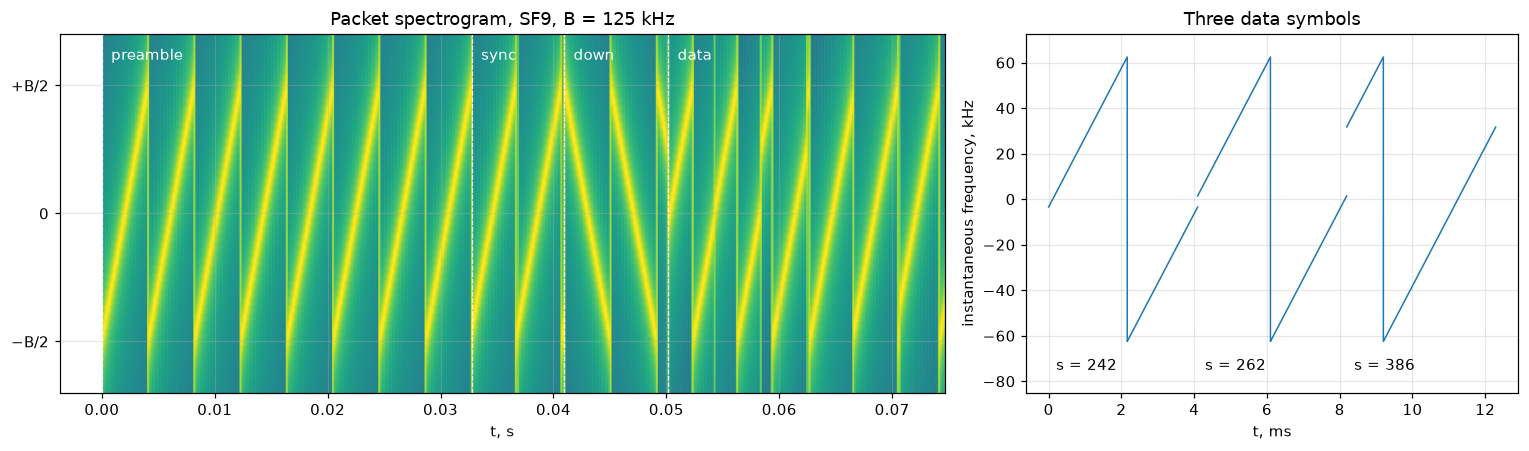

Packet: 9344.0 samples = 74.8 ms


In [3]:
OS = 8
data = rng.integers(0, N, 6)
parts = [chirp(np.zeros(8, int), SF, OS), chirp(np.array([24, 32]), SF, OS),
         chirp(np.zeros(3, int), SF, OS, down=True).ravel()[:int(2.25 * N * OS)], chirp(data, SF, OS)]
pkt = np.concatenate([p.ravel() for p in parts])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.8, 1]})
nfft = max(64, N * OS // 16)
ax[0].specgram(pkt, NFFT=nfft, Fs=OS * BW, noverlap=nfft * 3 // 4, cmap="viridis", sides="twosided")
ax[0].set_ylim(-0.7 * BW, 0.7 * BW)
ax[0].set_yticks(np.array([-0.5, 0, 0.5]) * BW, ["−B/2", "0", "+B/2"])
edges = np.cumsum([0, 8 * N, 2 * N, 2.25 * N, 6 * N]) / BW
for e, lab in zip(edges[:-1], ["preamble", "sync", "down", "data"]):
    ax[0].axvline(e, color="w", lw=0.8, ls="--"); ax[0].text(e + 0.2 * N / BW, 0.6 * BW, lab, color="w")
ax[0].set_xlabel("t, s"); ax[0].set_title(f"Packet spectrogram, SF{SF}, B = {BW/1e3:.0f} kHz")
for i, s in enumerate(data[:3]):
    t = (i * N * OS + np.arange(1, N * OS)) / (OS * BW) * 1e3
    ph = np.unwrap(np.angle(chirp(s, SF, OS)))
    ax[1].plot(t, np.diff(ph) / (2 * np.pi) * OS * BW / 1e3, "C0", lw=1)
    ax[1].text((i + 0.05) * N / BW * 1e3, -0.6 * BW / 1e3, f"s = {s}")
ax[1].set_ylim(-0.68 * BW / 1e3, 0.58 * BW / 1e3)
ax[1].set_xlabel("t, ms"); ax[1].set_ylabel("instantaneous frequency, kHz"); ax[1].set_title("Three data symbols")
plt.tight_layout(); plt.show()
print(f"Packet: {len(pkt) / OS} samples = {len(pkt) / OS / BW * 1e3:.1f} ms")

## 2. Dechirp: a signal under the noise
SNR = `SNR_DB` in band $B$: the signal is invisible in the time domain, and the noise standard deviation exceeds the amplitude. After multiplying by the down-chirp, symbol $s$ becomes a tone, and the FFT collects its energy into one bin, a peak $10\log_{10}N+\text{SNR}$ above the noise floor.

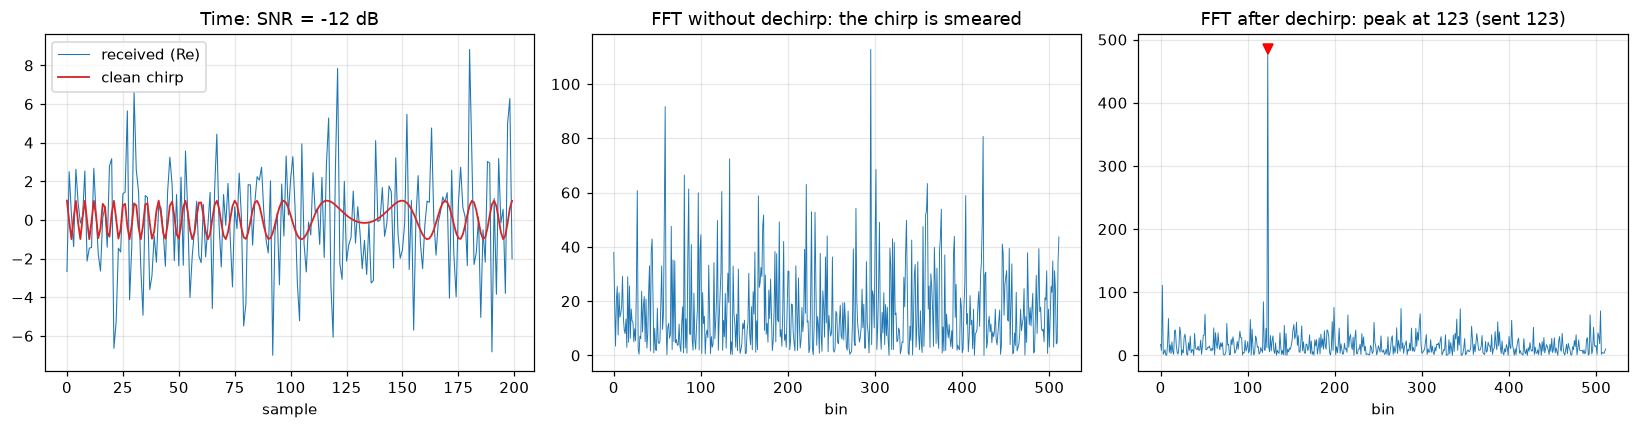

Peak above the mean noise floor: 14.9 dB (theory 10·log10(N·SNR) = 15.1 dB)


In [4]:
s0 = 123 % N
r = chirp(s0, SF) + awgn(N, SNR_DB, rng)
sh, Y = demod(r, SF, return_spec=True)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(r.real[:200], lw=0.7, label="received (Re)"); ax[0].plot(chirp(s0, SF).real[:200], "C3", lw=1.2, label="clean chirp")
ax[0].set_xlabel("sample"); ax[0].legend(); ax[0].set_title(f"Time: SNR = {SNR_DB} dB")
ax[1].plot(np.abs(np.fft.fft(r))**2 / N, lw=0.6)
ax[1].set_xlabel("bin"); ax[1].set_title("FFT without dechirp: the chirp is smeared")
P = np.abs(Y)**2 / N
ax[2].plot(P, lw=0.6); ax[2].plot(sh, P[sh], "rv")
ax[2].set_xlabel("bin"); ax[2].set_title(f"FFT after dechirp: peak at {sh} (sent {s0})")
plt.tight_layout(); plt.show()
noise_floor = np.median(P) / np.log(2)                       # median of Exp(μ) = μ·ln2
print(f"Peak above the mean noise floor: {10*np.log10(P[sh]/noise_floor):.1f} dB "
      f"(theory 10·log10(N·SNR) = {10*np.log10(N)+SNR_DB:.1f} dB)")

## 3. SER vs. SNR for SF7…SF12
An error happens when one of the $N-1$ noise bins exceeds the signal bin:
$$P_s=1-\int_0^\infty p_\text{Rice}(x)\,\big(1-e^{-x}\big)^{N-1}dx$$
Each SF step doubles $N$. The symbol energy grows by 3 dB, but there are also twice as many competing noise bins, so the threshold moves by ~2.5 dB. Dots are simulation, lines are the formula.

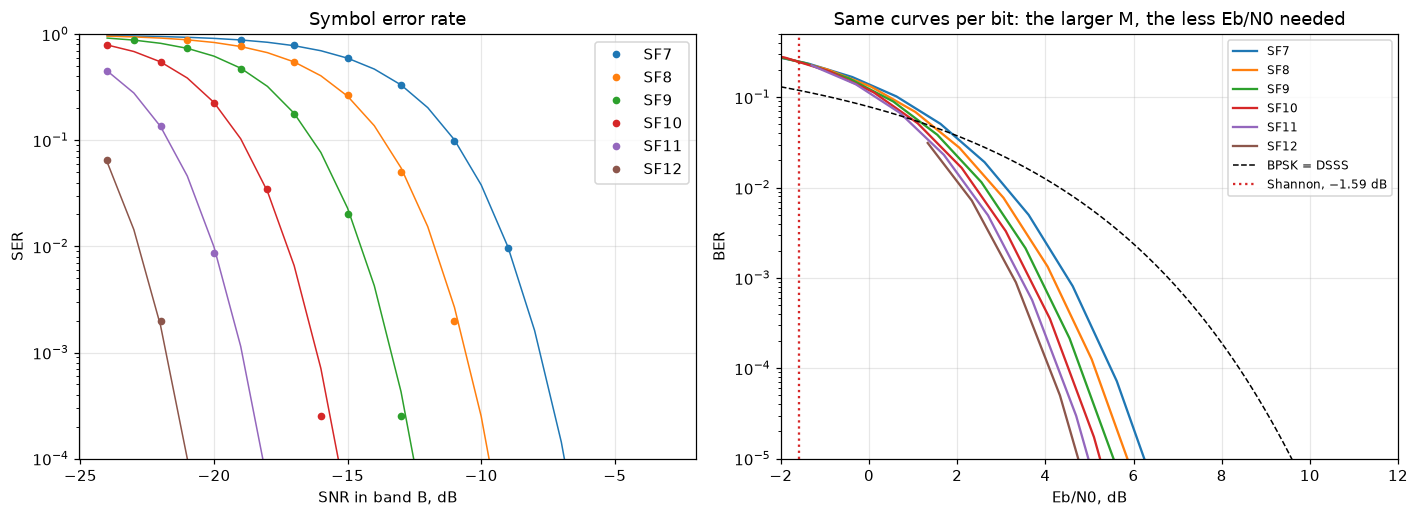

In [5]:
sfs = range(7, 13)
snr_grid = np.arange(-24, -2.9, 1.0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
thr = {}
for i, sf in enumerate(sfs):
    th = ser_theory(sf, snr_grid)
    ax[0].semilogy(snr_grid, th, f"C{i}-", lw=1)
    pts = snr_grid[(th > 3e-4) & (th < 0.9)][::2]
    ax[0].semilogy(pts, [sim_ser(sf, s, 4000, rng) for s in pts], f"C{i}o", ms=4, label=f"SF{sf}")
    thr[sf] = np.interp(-3, np.log10(th[::-1] + 1e-300), snr_grid[::-1])
    ebn0 = snr_grid + 10 * np.log10(2**sf / sf)              # Eb/N0 = SNR·N/SF
    ber = th * (2**sf / 2) / (2**sf - 1)
    ax[1].semilogy(ebn0, ber, f"C{i}-", label=f"SF{sf}")
from scipy.special import erfc
eb = np.linspace(-2, 12, 200)
ax[1].semilogy(eb, 0.5 * erfc(np.sqrt(10 ** (eb / 10))), "k--", lw=1, label="BPSK = DSSS")
ax[1].axvline(-1.59, color="C3", ls=":", label="Shannon, −1.59 dB")
ax[0].set_ylim(1e-4, 1); ax[0].set_xlabel("SNR in band B, dB"); ax[0].set_ylabel("SER"); ax[0].legend(); ax[0].set_title("Symbol error rate")
ax[1].set_ylim(1e-5, 0.5); ax[1].set_xlim(-2, 12); ax[1].set_xlabel("Eb/N0, dB"); ax[1].set_ylabel("BER")
ax[1].legend(fontsize=8); ax[1].set_title("Same curves per bit: the larger M, the less Eb/N0 needed")
plt.tight_layout(); plt.show()

### Link budget
Sensitivity $P_\text{min}=-174\ \text{dBm/Hz}+10\log_{10}B+NF+\text{SNR}_\text{min}$ ($NF=6$ dB). The table shows the SNR for SER $10^{-3}$ from the formula above (the Semtech datasheet gives −7.5…−20 dB, with a different criterion and a real receiver), the bit rate with coding rate 4/5, and the time on air of a 20-byte packet. In free space, +6 dB of margin = 2× range; in a city (path loss $\propto d^{3.5}$) it's 1.5×.

In [6]:
print(f" SF | SNR_min | Eb/N0 | sensitiv. | R_b, bit/s | 20 B on air | range ×(n=2) ×(n=3.5)")
for sf in sfs:
    sens = -174 + 10 * np.log10(BW) + 6 + thr[sf]
    d = thr[7] - thr[sf]
    print(f" {sf:2} | {thr[sf]:6.1f}  | {thr[sf] + 10*np.log10(2**sf/sf):5.1f} | {sens:6.1f} dBm | {bitrate(sf):9.0f}  | "
          f"{time_on_air(20, sf)*1e3:8.0f} ms  |    {10**(d/20):4.1f}    {10**(d/35):4.1f}")
print("\nEach SF step: ~+2.5 dB of link budget and ~2× the time on air (battery, 1 % duty cycle in Europe).")

 SF | SNR_min | Eb/N0 | sensitiv. | R_b, bit/s | 20 B on air | range ×(n=2) ×(n=3.5)
  7 |   -7.8  |   4.8 | -124.8 dBm |      5469  |       57 ms  |     1.0     1.0
  8 |  -10.6  |   4.5 | -127.6 dBm |      3125  |      103 ms  |     1.4     1.2
  9 |  -13.4  |   4.2 | -130.4 dBm |      1758  |      185 ms  |     1.9     1.4
 10 |  -16.2  |   3.9 | -133.2 dBm |       977  |      371 ms  |     2.6     1.7
 11 |  -19.0  |   3.7 | -136.0 dBm |       537  |      741 ms  |     3.6     2.1
 12 |  -21.8  |   3.5 | -138.8 dBm |       293  |     1319 ms  |     5.0     2.5

Each SF step: ~+2.5 dB of link budget and ~2× the time on air (battery, 1 % duty cycle in Europe).


## 4. Frequency and time offsets: one and the same axis
For a chirp, frequency and time are coupled: a shift of $\Delta t$ samples is a frequency shift of $\Delta t\cdot B/N$. So after dechirp, both a carrier offset $\Delta f$ (in bins, $\delta=\Delta f\,N/B$) and a window offset $\tau$ do the same thing: they **shift the peak**:
$$\text{up-chirp: } k_\uparrow=\tau+\delta,\qquad \text{down-chirp: } k_\downarrow=-\tau+\delta$$
That is why the preamble contains down-chirps: two equations → $\delta=(k_\uparrow+k_\downarrow)/2$, $\tau=(k_\uparrow-k_\downarrow)/2$. The fractional part of $\delta$ comes from the phase rotation of the peak between consecutive preamble up-chirps: a tone at $\delta$ bins accumulates $2\pi\delta$ over $N$ samples.

Crystals at ±`PPM` ppm at `FC_MHZ` MHz give kilohertz offsets, hundreds of bins at SF12. Without estimation from the preamble, the receiver misses by the whole offset.

True: δ = 29.509 bins (7204 Hz), τ = 37. Estimate: δ̂ = 29.486, τ̂ = 37
Data SER at SNR -12 dB: no correction 1.00, integer part of δ only 0.543, full correction 0.000


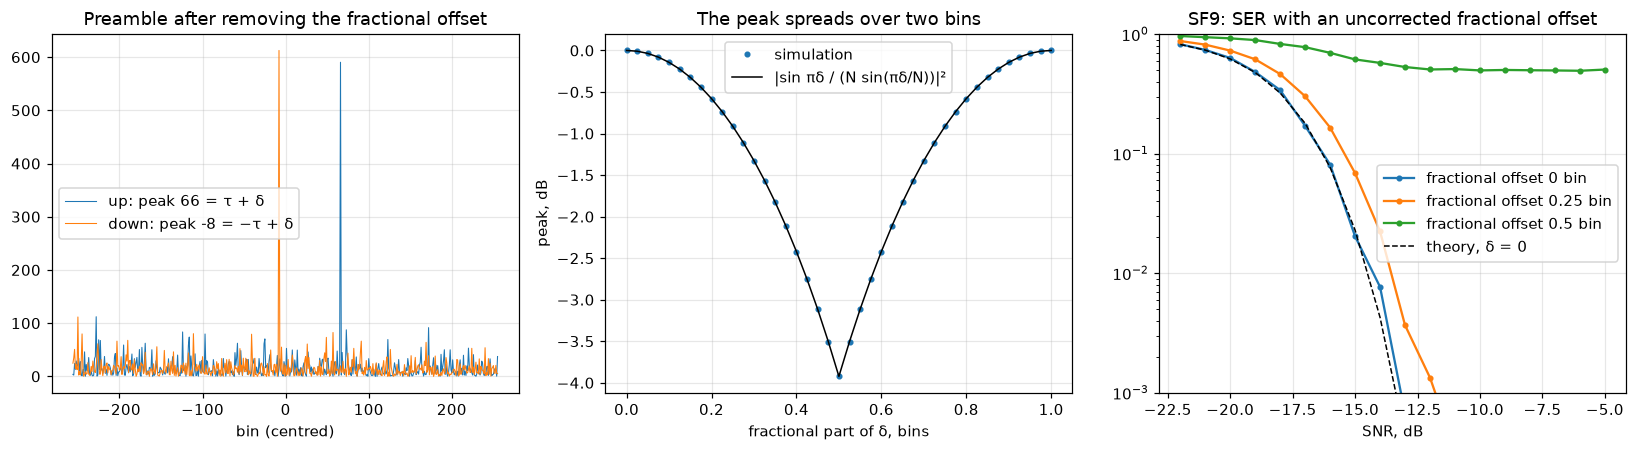

In [7]:
cfo_hz = PPM * 1e-6 * FC_MHZ * 1e6 * 0.83                     # some offset within ±PPM
delta = cfo_hz / (BW / N)
def rx(x, delta, tau, snr_db, rng):
    """Frequency offset of delta bins, receiver window tau samples late, noise."""
    n = np.arange(len(x))
    y = x * np.exp(2j * np.pi * delta * n / N) * np.exp(1j * rng.uniform(0, 2 * np.pi))
    y = np.r_[y, np.zeros(N)][tau:tau + len(x)]
    return y + awgn(len(y), snr_db, rng)

pre = np.r_[chirp(np.zeros(8, int), SF).ravel(), chirp(np.zeros(2, int), SF, down=True).ravel()]
data = rng.integers(0, N, 200)
tx = np.r_[pre, chirp(data, SF).ravel()]
y = rx(tx, delta, TIMING, SNR_DB, rng)

wrap = lambda k: (k + N // 2) % N - N // 2
def preamble_peaks(y):
    """Up-chirp windows 1…6 and the first down-chirp window lie entirely inside their segments for 0 ≤ τ < N."""
    Yu = np.fft.fft(y[N:7 * N].reshape(6, N) * chirp(0, SF, down=True), axis=1)
    Yd = np.fft.fft(y[8 * N:9 * N] * chirp(0, SF))
    return Yu, Yd
# step 1: fractional part of δ from the peak's phase advance between consecutive up-chirps (independent of τ)
Yu, Yd = preamble_peaks(y)
pk = np.abs(Yu).sum(0).argmax()
d_frac = np.angle(np.sum(Yu[1:, pk] * np.conj(Yu[:-1, pk]))) / (2 * np.pi)
# step 2: remove the fractional part → the peaks land exactly on integer bins τ+δ_int and −τ+δ_int
y_c = y * np.exp(-2j * np.pi * d_frac * np.arange(len(y)) / N)
Yu, Yd = preamble_peaks(y_c)
ku = wrap(np.abs(Yu).sum(0).argmax()); kd = wrap(np.abs(Yd).argmax())
d_int = (ku + kd) / 2; tau_hat = (ku - kd) / 2
d_hat = d_int + d_frac

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
kk = np.arange(N) - N // 2
ax[0].plot(kk, np.fft.fftshift(np.abs(Yu[2])**2) / N, lw=0.7, label=f"up: peak {ku} = τ + δ")
ax[0].plot(kk, np.fft.fftshift(np.abs(Yd)**2) / N, lw=0.7, label=f"down: peak {kd} = −τ + δ")
ax[0].set_xlabel("bin (centred)"); ax[0].legend(); ax[0].set_title(f"Preamble after removing the fractional offset")

def demod_data(y, d_hat, tau_hat, n):
    n0 = 10 * N - int(round(tau_hat))
    seg = y[n0:n0 + n * N]
    seg = seg * np.exp(-2j * np.pi * d_hat * np.arange(len(seg)) / N)
    seg = np.r_[seg, np.zeros(n * N - len(seg))]
    return demod(seg.reshape(n, N), SF)
ser_none = np.mean(demod(y[10 * N:10 * N + 199 * N].reshape(199, N), SF) != data[:199])
ser_int = np.mean(demod_data(y, np.round(d_int), tau_hat, 199) != data[:199])
ser_full = np.mean(demod_data(y, d_hat, tau_hat, 199) != data[:199])
print(f"True: δ = {delta:.3f} bins ({cfo_hz:.0f} Hz), τ = {TIMING}. Estimate: δ̂ = {d_hat:.3f}, τ̂ = {tau_hat:.0f}")
print(f"Data SER at SNR {SNR_DB} dB: no correction {ser_none:.2f}, integer part of δ only {ser_int:.3f}, full correction {ser_full:.3f}")

# loss from a fractional offset
fr = np.linspace(0, 1, 41)
meas = [np.abs(np.fft.fft(chirp(0, SF) * np.exp(2j * np.pi * f * np.arange(N) / N) * chirp(0, SF, down=True))).max()**2 / N**2 for f in fr]
th = np.abs(np.sin(np.pi * np.minimum(fr, 1 - fr)) / (N * np.sin(np.pi * np.minimum(fr, 1 - fr) / N) + 1e-30))**2
th[np.minimum(fr, 1 - fr) == 0] = 1
ax[1].plot(fr, 10 * np.log10(meas), "C0o", ms=3, label="simulation")
ax[1].plot(fr, 10 * np.log10(th), "k", lw=1, label="|sin πδ / (N sin(πδ/N))|²")
ax[1].set_xlabel("fractional part of δ, bins"); ax[1].set_ylabel("peak, dB"); ax[1].legend(); ax[1].set_title("The peak spreads over two bins")

snr_g = np.arange(-22, -4, 1.0) + (SF - 9) * -2.5
for i, f in enumerate([0, 0.25, 0.5]):
    ax[2].semilogy(snr_g, [sim_ser(SF, s, 3000, rng, cfo_bins=f) for s in snr_g], f"C{i}o-", ms=3, label=f"fractional offset {f} bin")
ax[2].semilogy(snr_g, ser_theory(SF, snr_g), "k--", lw=1, label="theory, δ = 0")
ax[2].set_ylim(1e-3, 1); ax[2].set_xlabel("SNR, dB"); ax[2].legend(); ax[2].set_title(f"SF{SF}: SER with an uncorrected fractional offset")
plt.tight_layout(); plt.show()

## 5. Interference: a tone and other SFs
**Narrowband interference.** After multiplying by the down-chirp, a tone itself becomes a chirp and is smeared over all $N$ bins, exactly like the jammer in DSSS. Left: a tone `JSR_DB` dB stronger than the signal, and the peak is still in place.

**Quasi-orthogonality of SFs.** An SF$_b$ chirp demodulated with an SF$_a\ne$SF$_b$ down-chirp is still a chirp (the sweep rates $B^2/2^{SF}$ differ, so a difference remains), and its energy also spreads over the bins. So different SFs on the same frequency barely disturb each other, which gives a LoRaWAN gateway 6 "logical channels" on one frequency. "Barely": the matrix on the right shows the signal-to-interference ratio (SIR) at which the wanted signal's SER drops to 1 % (no noise, interferer with random time and phase offset). The diagonal is the same SF: **capture**, the strongest wins. Without noise the threshold is ≈0 dB (the energy of an unsynchronized interferer splits between two bins); a real receiver with noise and fading needs +1…+6 dB.

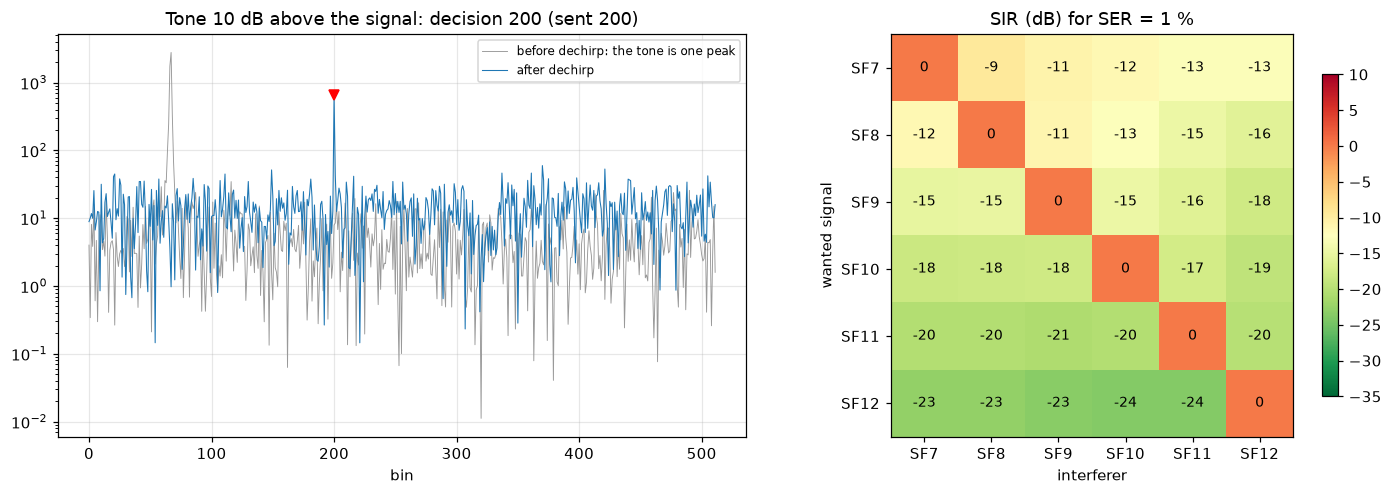

Below zero: the wanted signal is weaker than the interferer and is still received.
Diagonal (same SF, capture): [0.1 0.  0.  0.  0.  0. ] dB


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
s0 = 200 % N
n = np.arange(N)
tone = 10 ** (JSR_DB / 20) * np.exp(2j * np.pi * (0.13 * n + rng.random()))
r = chirp(s0, SF) + tone + awgn(N, SNR_DB + 6, rng)
sh, Y = demod(r, SF, return_spec=True)
ax[0].plot(np.abs(np.fft.fft(r))**2 / N, "0.6", lw=0.6, label="before dechirp: the tone is one peak")
ax[0].plot(np.abs(Y)**2 / N, "C0", lw=0.7, label="after dechirp")
ax[0].plot(sh, np.abs(Y[sh])**2 / N, "rv")
ax[0].set_yscale("log"); ax[0].set_xlabel("bin"); ax[0].legend(fontsize=8)
ax[0].set_title(f"Tone {JSR_DB} dB above the signal: decision {sh} (sent {s0})")

def interferer(sf_i, n_samp, rng):
    """A continuous stream of SF_i symbols with a random time and phase offset."""
    Ni = 2**sf_i
    k = n_samp // Ni + 2
    x = chirp(rng.integers(0, Ni, k), sf_i).ravel()
    off = rng.integers(0, Ni)
    return x[off:off + n_samp] * np.exp(1j * rng.uniform(0, 2 * np.pi))

def ser_sir(sf_a, sf_b, sir_db, n_sym, rng):
    Na = 2**sf_a
    s = rng.integers(0, Na, n_sym)
    I = np.stack([interferer(sf_b, Na, rng) for _ in range(n_sym)])
    r = chirp(s, sf_a) + 10 ** (-sir_db / 20) * I
    return np.mean(demod(r, sf_a) != s)

sir_grid = np.arange(-40, 12, 1.0)
Mthr = np.full((6, 6), np.nan)
for a, sfa in enumerate(sfs):
    for b, sfb in enumerate(sfs):
        lo, hi = -45.0, 15.0                                  # bisection: SER(SIR) is monotonic
        for _ in range(9):
            mid = (lo + hi) / 2
            if ser_sir(sfa, sfb, mid, 300 if sfa < 11 else 150, rng) > 0.01: lo = mid
            else: hi = mid
        Mthr[a, b] = hi
im = ax[1].imshow(Mthr, cmap="RdYlGn_r", vmin=-35, vmax=10)
for a in range(6):
    for b in range(6):
        ax[1].text(b, a, f"{Mthr[a, b]:.0f}", ha="center", va="center", fontsize=9)
ax[1].set_xticks(range(6), [f"SF{s}" for s in sfs]); ax[1].set_yticks(range(6), [f"SF{s}" for s in sfs])
ax[1].set_xlabel("interferer"); ax[1].set_ylabel("wanted signal"); ax[1].grid(False)
ax[1].set_title("SIR (dB) for SER = 1 %"); plt.colorbar(im, ax=ax[1], shrink=0.8)
plt.tight_layout(); plt.show()
print("Below zero: the wanted signal is weaker than the interferer and is still received.")
print(f"Diagonal (same SF, capture): {np.round(np.diag(Mthr), 1)} dB")

## Comparison with CDMA and LTE
| | DSSS / CDMA | CSS / LoRa | OFDM / LTE |
|---|---|---|---|
| What spreads the spectrum | PN sequence, $N$ chips per **1 bit** | chirp, $N$ samples per **SF bits** | nothing: $N$ parallel streams |
| Gain against white noise | 0 dB (BPSK) | grows with SF (orthogonal $M$-ary) | 0; the gain comes from the code |
| Narrowband interference | suppressed by $N$ | suppressed by $N$ | hits its own subcarriers; the code recovers them |
| Synchronization | code phase search (correlation) | one FFT: time and frequency are one peak shift | CP + pilots, sensitive to frequency offset |
| Peak-to-average ratio | low | **0 dB**: a cheap non-linear amplifier | high |
| Spectral efficiency | low | very low: $SF/2^{SF}$ bit/s/Hz | high |

Why a chirp and not plain $M$-FSK with the same $N$ tones? Each FSK symbol is a **narrow** line, which a spectral null or a narrowband interferer can wipe out. Each chirp symbol sweeps the whole band $B$. That gives frequency diversity within a symbol and interference suppression while keeping a constant envelope. The price is the same as for DSSS: bandwidth and rate.

## Things to try
- `SNR_DB = -20` with `SF = 12`: sections 2 and 4 still work. With `SF = 7` they don't: the SF7 threshold is around −7…−8 dB
- `PPM = 40` (cheap crystals): at small SFs the offset exceeds $N/2$ bins and the preamble estimate wraps around. This is why SF11–12 come with a drift limit and the LDRO mode
- `TIMING` larger than `N // 2`: the τ estimate from the preamble is ambiguous modulo $N$. In practice the first coarse search slides a window along the preamble
- `BW = 500e3`: the same picture 4× faster, but sensitivity is 6 dB worse (more noise in the band)
- `JSR_DB = 30` with `SF = 7`: the tone breaks through, since suppression is limited to $10\log_{10}N=21$ dB
- in `ser_sir`, remove the random time offset (`off = 0`): a same-SF interferer aligned to the symbols behaves differently, because now it's two tones in one FFT